# Entrenar YOLO nano para reconocer nuestros peluches

Este notebook usa imagenes_peluchesv3, que ya incluye la división y los aumentos exportados de Roboflow.

El flujo es: configurar entorno → revisar datos y etiquetas → entrenar → validar → evaluar test → predecir → guardar pesos.

**Antes de ejecutar:** en la terminal, desde la raíz del repo, ejecuta `uv sync` y selecciona `.venv/bin/python` como kernel de este notebook en VS Code.

Ejecuta las celdas en orden. El entrenamiento utiliza los pesos preentrenados `yolo26n.pt`, que se descargan la primera vez. El dataset contiene tres clases propias; no se garantiza conservar las categorías originales de COCO.


In [3]:
from pathlib import Path
from collections import Counter
import hashlib
import sys

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from IPython.display import Image as NotebookImage, display
import torch
from ultralytics import YOLO
import yaml


## 1. Configurar rutas y entrenamiento

El notebook encuentra la raíz tanto si el kernel se inicia en el repo como en una subcarpeta. Selecciona CUDA si hay una GPU NVIDIA, MPS si PyTorch puede usar la GPU de Apple, o CPU como alternativa. Puedes cambiar `DEVICE` manualmente. CPU funciona, pero el entrenamiento tarda más.

Empieza con 50 épocas, imágenes de 640 píxeles y lotes de 4. `patience=10` permite detenerse si la validación deja de mejorar. Son parámetros iniciales, no una garantía de precisión.


In [4]:
ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "pyproject.toml").is_file()
     and (p / "imagenes_peluchesv3" / "data.yaml").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Abre este notebook desde el repositorio y conserva imagenes_peluchesv3/data.yaml.")

DATASET_DIR = ROOT / "imagenes_peluchesv3"
OUTPUT_DIR = ROOT / "runs" / "peluches"
MODEL_WEIGHTS = "yolo26n.pt"
EPOCHS = 50
IMAGE_SIZE = 640
BATCH_SIZE = 4
DEVICE = 0 if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")

print("Dataset:", DATASET_DIR)
print("Dispositivo:", DEVICE)
print("Resultados:", OUTPUT_DIR)


Dataset: /Users/martinrestrepocoral/Desktop/IA/yolo_nao/imagenes_peluchesv3
Dispositivo: mps
Resultados: /Users/martinrestrepocoral/Desktop/IA/yolo_nao/runs/peluches


## 2. Preparar el archivo de configuración

El export de Roboflow contiene rutas `../train/images`, etc. Creamos un YAML local con rutas inequívocas, sin modificar el export original. Los IDs y nombres de clases se conservan tal como fueron etiquetados. Los aumentos de Roboflow ya están en `train`; validación y test se mantienen separados.


In [5]:
with (DATASET_DIR / "data.yaml").open() as f:
    exported_config = yaml.safe_load(f)

names = exported_config["names"]
CLASS_NAMES = names if isinstance(names, list) else [names[i] for i in range(len(names))]
assert exported_config.get("nc", len(CLASS_NAMES)) == len(CLASS_NAMES)

config = {
    "path": str(DATASET_DIR.resolve()),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": len(CLASS_NAMES),
    "names": CLASS_NAMES,
}
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_YAML = OUTPUT_DIR / "dataset.yaml"
DATA_YAML.write_text(yaml.safe_dump(config, sort_keys=False, allow_unicode=True))
print(DATA_YAML.read_text())


path: /Users/martinrestrepocoral/Desktop/IA/yolo_nao/imagenes_peluchesv3
train: train/images
val: valid/images
test: test/images
nc: 3
names:
- peluche_Juan Jose
- peluche_martin
- peluche_sebastian



## 3. Comprobar imágenes y etiquetas

Verificamos que cada imagen se pueda leer, que tenga archivo de etiquetas y que cada caja use un ID válido y coordenadas normalizadas. Un archivo de etiquetas vacío es válido para una imagen negativa. Mostramos las cajas por clase para detectar clases con muy pocos ejemplos.

También comprobamos duplicados exactos entre grupos. Esto no detecta fotos casi iguales ni variantes aumentadas; esas deben revisarse por sesión de captura.


In [6]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
images_by_split = {}
errors = []
hashes = {}

for split in ("train", "valid", "test"):
    image_dir = DATASET_DIR / split / "images"
    label_dir = DATASET_DIR / split / "labels"
    if not image_dir.is_dir() or not label_dir.is_dir():
        errors.append(f"Faltan carpetas images/labels de {split}")
        continue
    images = sorted(p for p in image_dir.iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS)
    images_by_split[split] = images
    if not images:
        errors.append(f"No hay imágenes en {split}")
    counts = Counter()
    for image_path in images:
        try:
            with Image.open(image_path) as im:
                im.verify()
        except Exception as exc:
            errors.append(f"Imagen inválida: {image_path.name}: {exc}")
        digest = hashlib.sha256(image_path.read_bytes()).hexdigest()
        if digest in hashes and hashes[digest] != split:
            errors.append(f"Imagen duplicada entre {hashes[digest]} y {split}: {image_path.name}")
        hashes[digest] = split
        label_path = label_dir / f"{image_path.stem}.txt"
        if not label_path.is_file():
            errors.append(f"Falta etiqueta: {label_path}")
            continue
        for line_number, line in enumerate(label_path.read_text().splitlines(), 1):
            if not line.strip():
                continue
            try:
                values = list(map(float, line.split()))
                assert len(values) == 5, "Se esperan clase, x, y, ancho y alto"
                cls, x, y, w, h = values
                assert cls.is_integer() and 0 <= cls < len(CLASS_NAMES), "Clase inválida"
                assert all(0 <= v <= 1 for v in (x, y, w, h)), "Coordenadas fuera de [0, 1]"
                assert w > 0 and h > 0, "Caja sin tamaño"
                counts[int(cls)] += 1
            except (ValueError, AssertionError) as exc:
                errors.append(f"{label_path.name}:{line_number}: {exc}")
    print(f"{split}: {len(images)} imágenes")
    for class_id, class_name in enumerate(CLASS_NAMES):
        print(f"  {class_name}: {counts[class_id]} cajas")
        if counts[class_id] == 0:
            errors.append(f"La clase {class_name} no aparece en {split}")

if errors:
    raise ValueError("Revisa el dataset:\n" + "\n".join(errors[:30]))
print("Dataset verificado.")


train: 452 imágenes
  peluche_Juan Jose: 148 cajas
  peluche_martin: 136 cajas
  peluche_sebastian: 132 cajas
valid: 65 imágenes
  peluche_Juan Jose: 21 cajas
  peluche_martin: 19 cajas
  peluche_sebastian: 21 cajas
test: 32 imágenes
  peluche_Juan Jose: 8 cajas
  peluche_martin: 8 cajas
  peluche_sebastian: 13 cajas
Dataset verificado.


En ROBOFLOW primero se reparten las imágenes originales entre entrenamiento, validación y test. Después, los aumentos se aplican solo al entrenamiento. Al aumentar las clases por igual, crece el grupo de entrenamiento y se conserva aproximadamente su proporción entre peluches; validación y test mantienen el balance que tenían. Esto puede beneficiar al modelo porque cada peluche tiene una presencia similar y aprende con variaciones de posición e iluminación. Los aumentos no corrigen un desbalance previo ni sustituyen fotos nuevas y variadas, y no garantizan mejores resultados. Validación y test conservan imágenes originales para evaluar el resultado.


## 4. Visualizar fotos con sus cajas

Comprueba que las cajas rodeen al peluche correcto y que los nombres coincidan. Para ver otras imágenes, cambia `PREVIEW_SEED`.


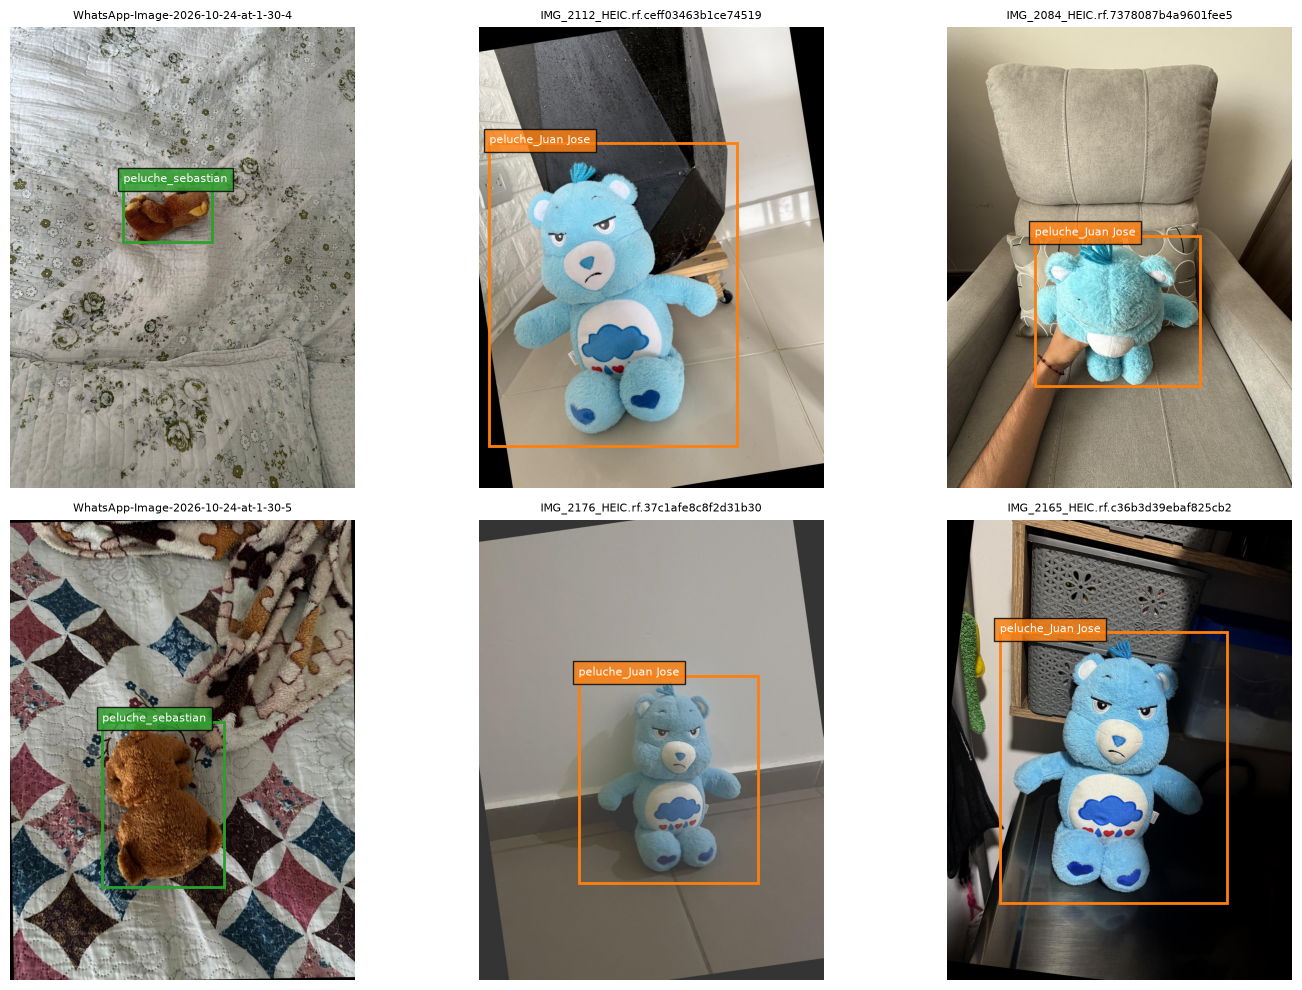

In [7]:
import random

PREVIEW_SEED = 42
sample = random.Random(PREVIEW_SEED).sample(
    images_by_split["train"], min(6, len(images_by_split["train"]))
)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
colors = ["tab:orange", "tab:blue", "tab:green"]
for ax, image_path in zip(axes.flat, sample):
    with Image.open(image_path) as source:
        image = source.convert("RGB")
    width, height = image.size
    ax.imshow(image)
    label_path = DATASET_DIR / "train" / "labels" / f"{image_path.stem}.txt"
    for line in label_path.read_text().splitlines():
        if not line.strip():
            continue
        cls, x, y, w, h = map(float, line.split())
        left, top = (x - w / 2) * width, (y - h / 2) * height
        color = colors[int(cls) % len(colors)]
        ax.add_patch(Rectangle((left, top), w * width, h * height,
                               fill=False, edgecolor=color, linewidth=2))
        ax.text(left, top, CLASS_NAMES[int(cls)], color="white",
                fontsize=8, bbox={"facecolor": color, "alpha": 0.8})
    ax.set_title(image_path.name[:35], fontsize=8)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 5. Cargar YOLO nano y entrenar

Equivale al bloque `model.train(...)` del ejemplo BCCD. Ejecutar esta celda inicia el entrenamiento real. Los resultados se guardan en la carpeta fija runs/peluches/train y se reutiliza al volver a entrenar.

Ultralytics también aplica aumentos durante el entrenamiento. Usamos ajustes moderados porque el dataset ya fue aumentado en Roboflow. Si falta memoria, baja `BATCH_SIZE` a 2 o 1.

La primera ejecución requiere internet para descargar `yolo26n.pt`.


In [8]:
model = YOLO(MODEL_WEIGHTS)
model.info()


YOLO26n summary: 260 layers, 2,572,280 parameters, 0 gradients, 6.2 GFLOPs


(260, 2572280, 0, 6.2396672)

In [9]:
results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    patience=10,
    workers=0,
    seed=42,
    project=str(OUTPUT_DIR),
    name="train",
    exist_ok=True,
    plots=True,
    val=True,
    degrees=0.0,
    fliplr=0.0,
    hsv_h=0.0,
    hsv_s=0.2,
    hsv_v=0.1,
    mosaic=0.0,
    translate=0.05,
    scale=0.1,
)

RUN_DIR = Path(model.trainer.save_dir)
BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
(RUN_DIR / "weights" / "last.pt").unlink(missing_ok=True)  # Conservar solo best.pt.
print("Resultados:", RUN_DIR)
print("Mejores pesos:", BEST_WEIGHTS)


New https://pypi.org/project/ultralytics/8.4.191 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.190 🚀 Python-3.14.3 torch-2.14.1 MPS (Apple M5 Pro)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/martinrestrepocoral/Desktop/IA/yolo_nao/runs/peluches/dataset.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.2, hsv_v=0.1, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train,

/Users/martinrestrepocoral/Desktop/IA/yolo_nao/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/50      2.23G     0.9067      33.37     0.0158          4        640: 100% ━━━━━━━━━━━━ 113/113 6.2it/s 18.2s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 4.3it/s 2.1s0.1s
                   all         65         61      0.982      0.944      0.994      0.711

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       2/50      2.27G     0.8773      9.862    0.01724          4        640: 0% ──────────── 0/113  0.5s

/Users/martinrestrepocoral/Desktop/IA/yolo_nao/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/50      2.23G     0.9489      5.841    0.01691          4        640: 100% ━━━━━━━━━━━━ 113/113 6.7it/s 16.8s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 7.1it/s 1.3s0.1s
                   all         65         61      0.934      0.895      0.976      0.742

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/50      2.27G     0.6525       2.42    0.01448          4        640: 0% ──────────── 0/113  0.5s

...

      48/50      2.24G     0.2373     0.1538   0.003865          4        640: 100% ━━━━━━━━━━━━ 113/113 6.5it/s 17.3s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 6.9it/s 1.3s0.1s
                   all         65         61      0.994      0.999      0.995      0.903

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size


/Users/martinrestrepocoral/Desktop/IA/yolo_nao/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      49/50      2.24G     0.2368     0.1527   0.003835          4        640: 100% ━━━━━━━━━━━━ 113/113 6.6it/s 17.0s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 7.2it/s 1.3s0.1s
                   all         65         61      0.995          1      0.995      0.898

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      50/50      2.26G     0.3315     0.1294   0.002904          4        640: 0% ──────────── 0/113  0.5s

/Users/martinrestrepocoral/Desktop/IA/yolo_nao/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      50/50      2.24G     0.2323     0.1434   0.003743          4        640: 100% ━━━━━━━━━━━━ 113/113 6.5it/s 17.3s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 6.6it/s 1.4s0.1s
                   all         65         61      0.995          1      0.995      0.897

50 epochs completed in 0.265 hours.
Optimizer stripped from /Users/martinrestrepocoral/Desktop/IA/yolo_nao/runs/peluches/train/weights/last.pt, 5.4MB
Optimizer stripped from /Users/martinrestrepocoral/Desktop/IA/yolo_nao/runs/peluches/train/weights/best.pt, 5.4MB

Validating /Users/martinrestrepocoral/Desktop/IA/yolo_nao/runs/peluches/train/weights/best.pt...
Ultralytics 8.4.190 🚀 Python-3.14.3 torch-2.14.1 MPS (Apple M5 Pro)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 9.3it/s 1.0s0.3s
                

## 6. Revisar curvas y ejemplos del entrenamiento

Las curvas y la validación ayudan a detectar sobreajuste. El rendimiento sobre imágenes nuevas es más importante que acertar todas las fotos de entrenamiento.

La matriz de confusión se muestra en la sección 7, después de ejecutar la validación de `best.pt` con `conf=0.25`.


results.png


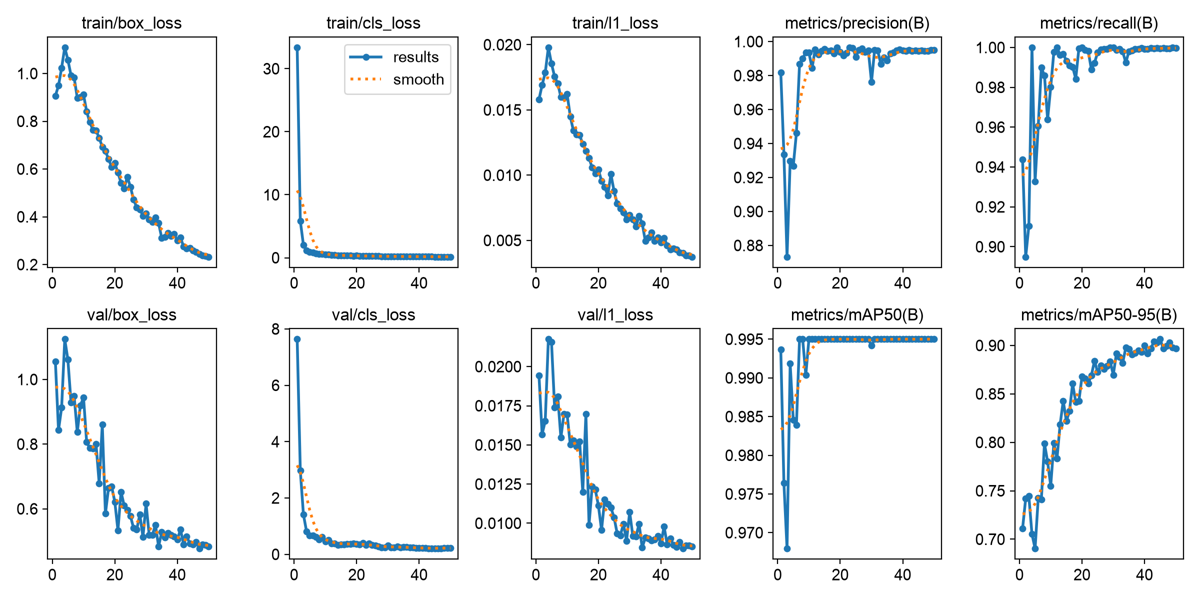

train_batch0.jpg


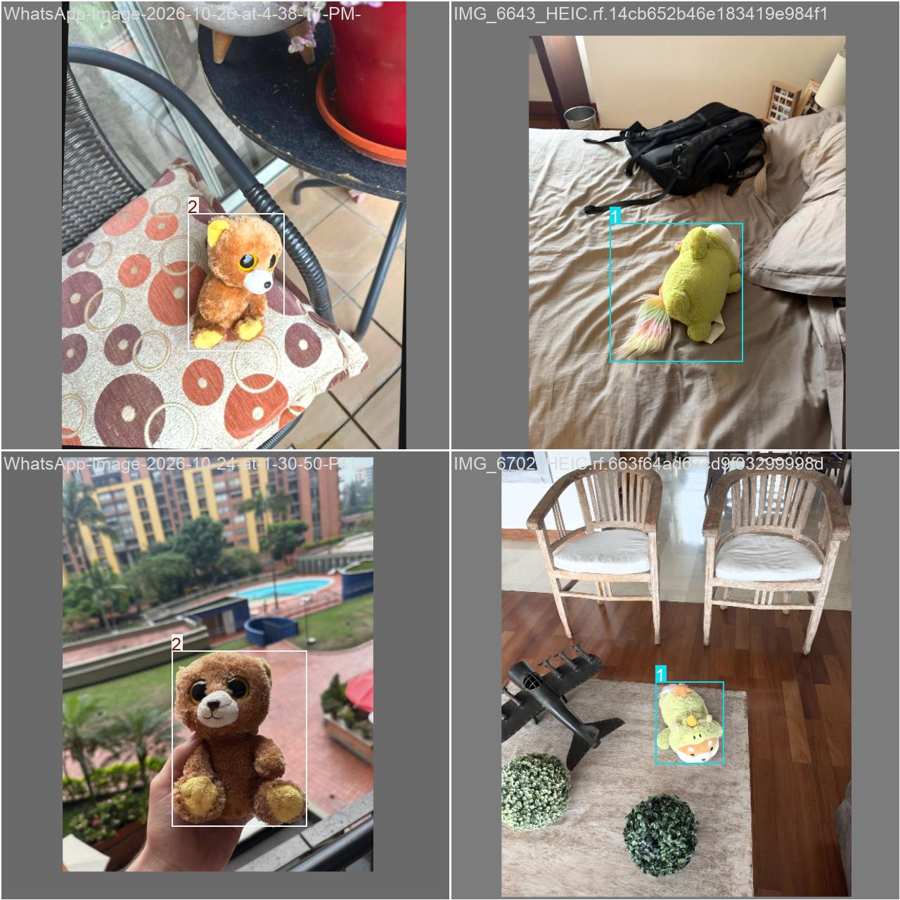

In [10]:
from IPython.display import display

for filename in ("results.png", "train_batch0.jpg"):
    path = RUN_DIR / filename
    if path.is_file():
        print(filename)
        with Image.open(path) as image:
            preview = image.copy()
        preview.thumbnail((1200, 900))
        display(preview)


## 7. Evaluar los mejores pesos en validación

Usamos `best.pt`, no el último estado de entrenamiento. mAP50 y mAP50-95 van de 0 a 1; cuanto más alto, mejor. Revisa también precisión y recall por clase.

Para regenerar las matrices con `conf=0.25`, ejecuta las secciones 7 y 8. Si reiniciaste el kernel, ejecuta primero los imports y las secciones 1 y 2; no ejecutes la sección 5 de entrenamiento. Al reiniciar, se usan los pesos existentes de `runs/peluches/train/weights/best.pt`; ajusta esa ruta si deseas evaluar otra ejecución. Los resultados se guardan en las carpetas fijas val y test dentro de runs/peluches. Al repetir la evaluación se reutilizan esas carpetas. Cambiar el umbral también afecta mAP.

La matriz se muestra debajo de las métricas y se carga de la carpeta de esta evaluación.


Ultralytics 8.4.190 🚀 Python-3.14.3 torch-2.14.1 MPS (Apple M5 Pro)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5615.1±2427.2 MB/s, size: 261.0 KB)
val: Scanning /Users/martinrestrepocoral/Desktop/IA/yolo_nao/imagenes_peluchesv3/valid/labels.cache... 65 images, 4 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 65/65 68.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 17.5it/s 1.0s0.1s
                   all         65         61          1          1      0.995      0.903
     peluche_Juan Jose         21         21          1          1      0.995      0.958
        peluche_martin         19         19          1          1      0.995      0.894
     peluche_sebastian         21         21          1          1      0.995      0.857
Speed: 0.3ms preprocess, 4.6ms inference, 0.0ms loss, 2.7ms postprocess per image
Results saved 

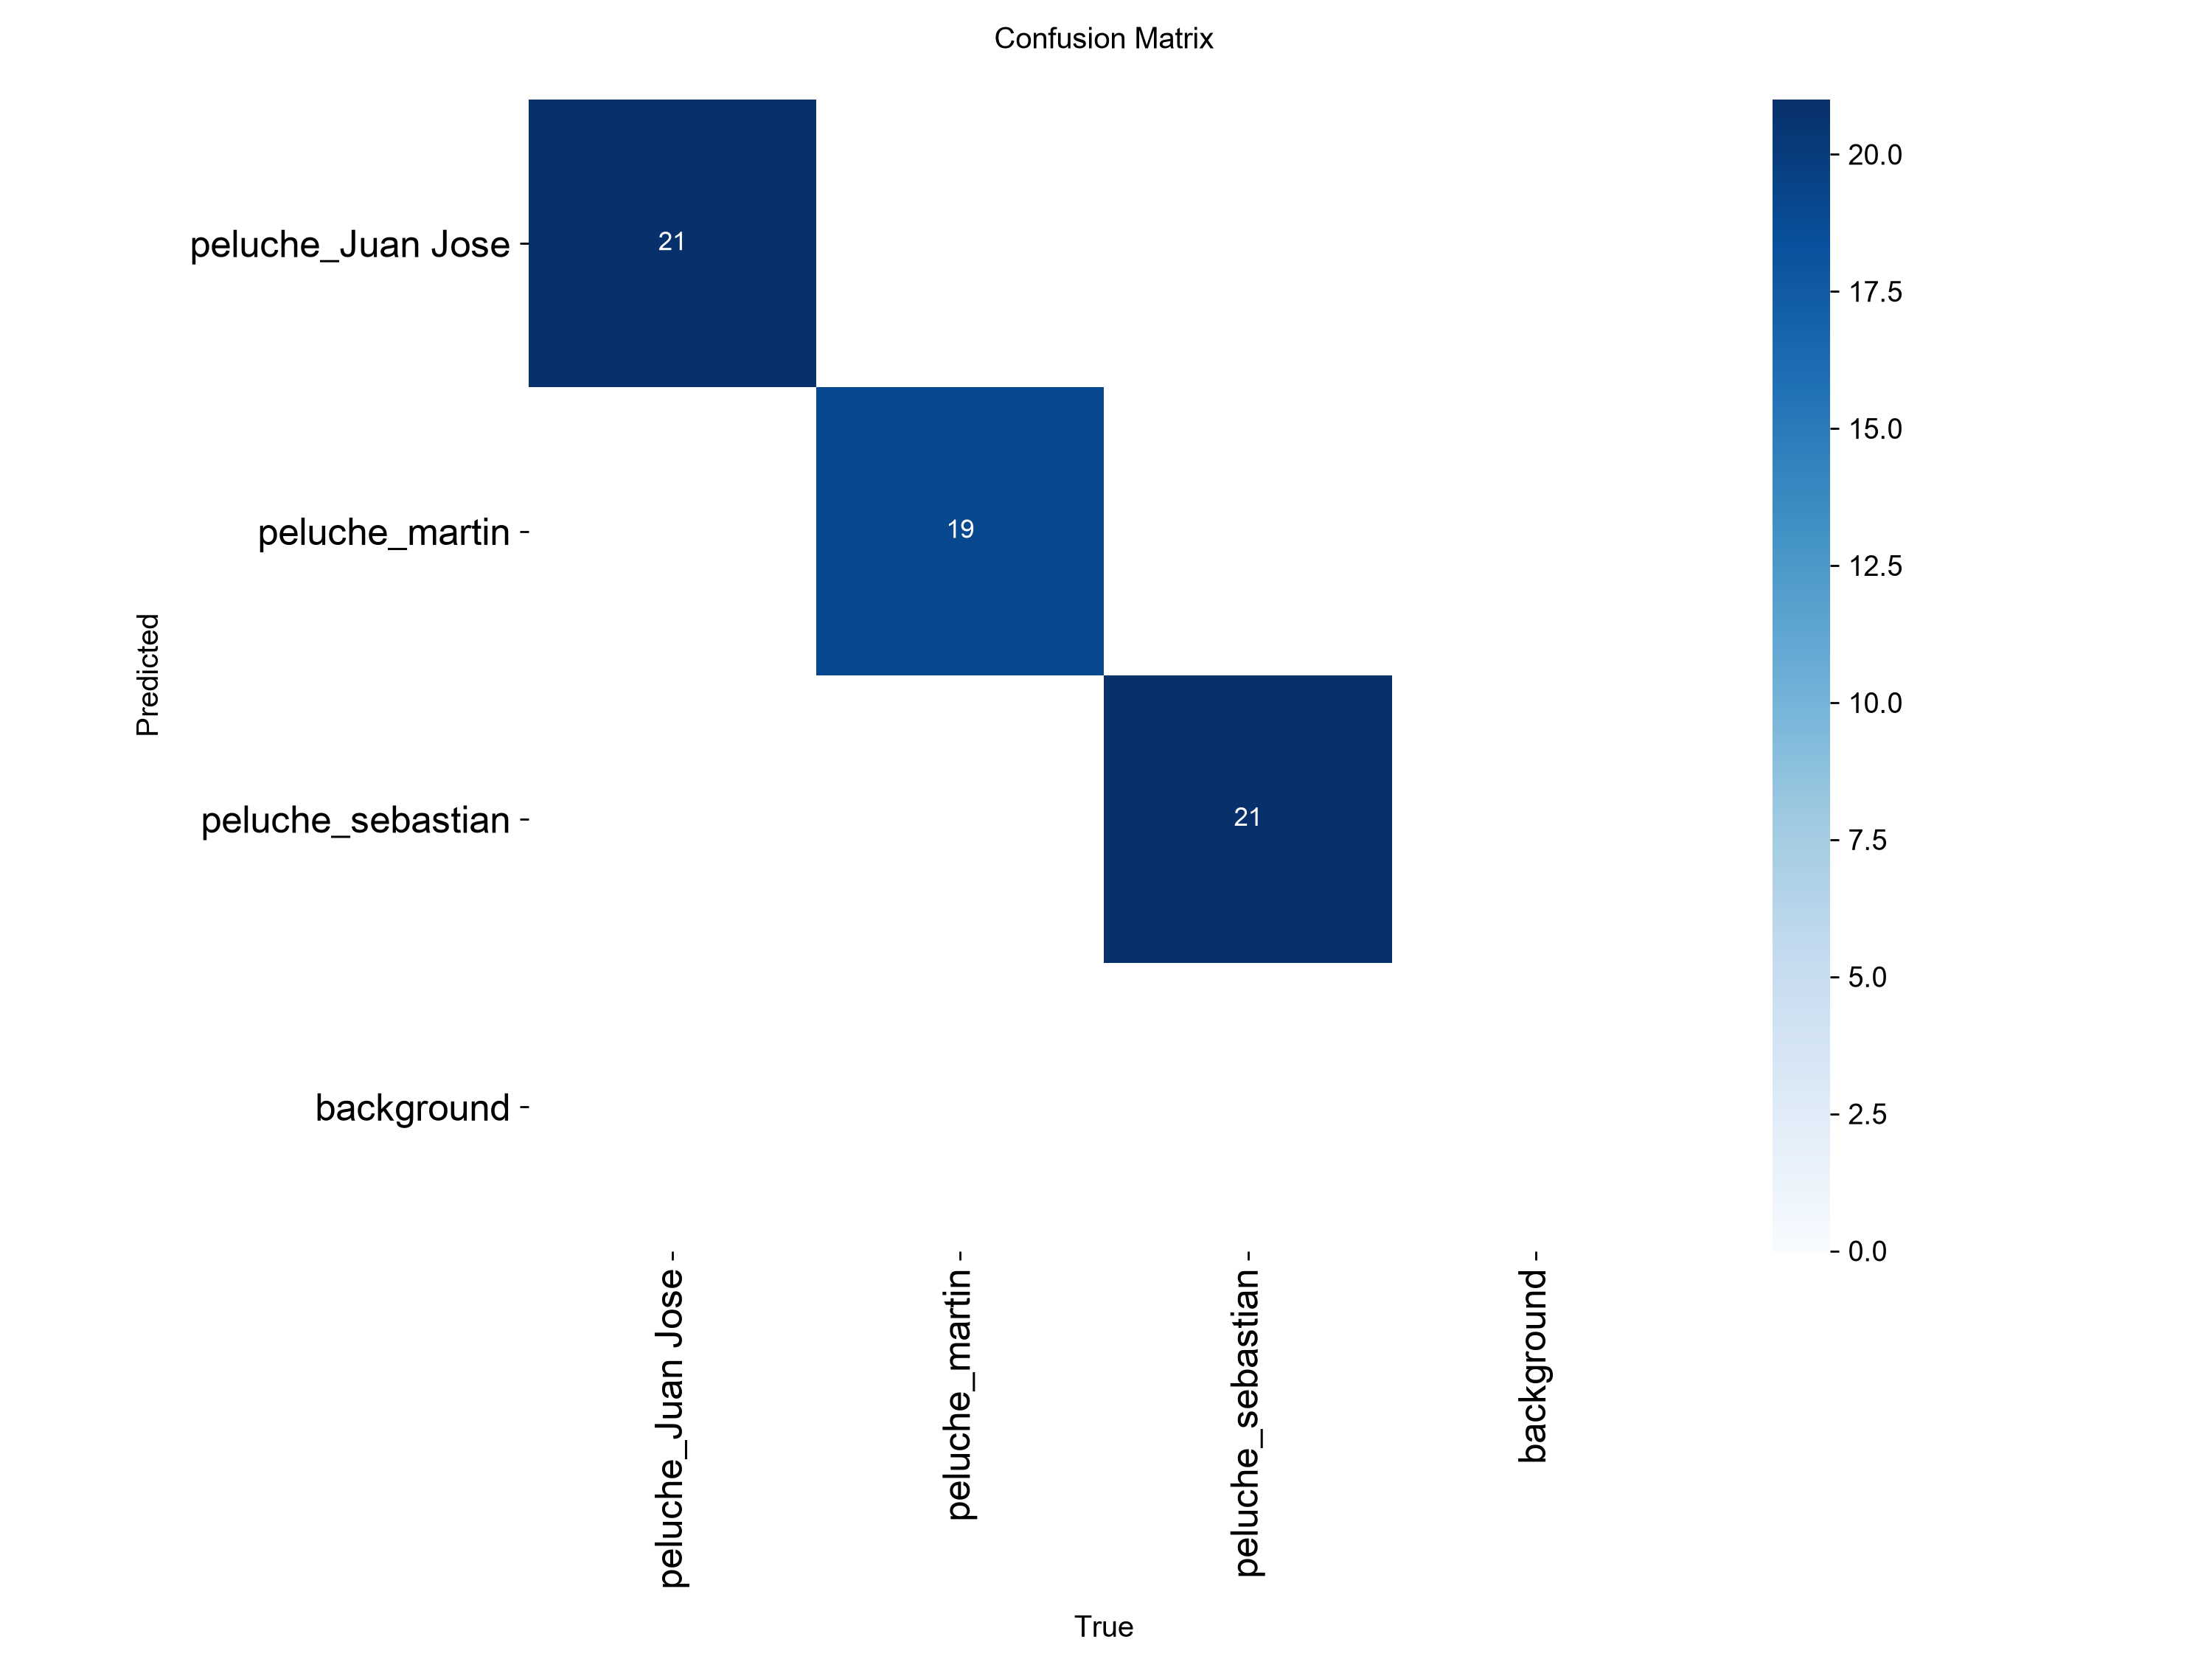

In [11]:
# Permite evaluar el entrenamiento existente sin volver a entrenar.
# Si reiniciaste el kernel, ejecuta primero imports y las secciones 1 y 2.
if "BEST_WEIGHTS" not in globals():
    BEST_WEIGHTS = OUTPUT_DIR / "train" / "weights" / "best.pt"
if not BEST_WEIGHTS.is_file():
    raise FileNotFoundError(f"No se encontraron los pesos entrenados: {BEST_WEIGHTS}")

best_model = YOLO(str(BEST_WEIGHTS))
validation = best_model.val(
    data=str(DATA_YAML), split="val", device=DEVICE,
    imgsz=IMAGE_SIZE, batch=BATCH_SIZE, workers=0,
    conf=0.25,
    project=str(OUTPUT_DIR), name="val", exist_ok=True, plots=True,
)
print(f"mAP50: {validation.box.map50:.3f}")
print(f"mAP50-95: {validation.box.map:.3f}")
for class_id, class_map in zip(validation.box.ap_class_index, validation.box.maps[validation.box.ap_class_index]):
    print(f"{CLASS_NAMES[int(class_id)]}: mAP50-95={class_map:.3f}")

# Mostrar la matriz de esta validación, con el umbral usado arriba.
from IPython.display import Image as NotebookImage, display
VALIDATION_DIR = Path(validation.save_dir)
print("Matriz de validación — conf=0.25:", VALIDATION_DIR)
display(NotebookImage(filename=str(VALIDATION_DIR / "confusion_matrix.png"), width=1000))


La fila Predicted background significa que el modelo no produjo una detección válida para un objeto etiquetado. Por ejemplo, un 1 en esa fila y en la columna peluche_Juan Jose indicaría que un peluche de Juan José quedó sin detectar; no es un fondo reconocido correctamente. La columna True background cuenta las detecciones sin un objeto etiquetado correspondiente. Al subir conf se filtran detecciones de baja confianza, lo que puede reducir falsas detecciones pero también dejar peluches sin detectar.


Aumentar el conf nos permitió reducir casi todas las falsas detecciones, ya que podia haber detecciones falsas con muy baja confianza, que ahora son filtradas

## 8. Evaluación final con test


Ultralytics 8.4.190 🚀 Python-3.14.3 torch-2.14.1 MPS (Apple M5 Pro)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 696.0±584.1 MB/s, size: 195.5 KB)
val: Scanning /Users/martinrestrepocoral/Desktop/IA/yolo_nao/imagenes_peluchesv3/test/labels.cache... 32 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 32/32 33.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 20.3it/s 0.4s0.1s
                   all         32         29      0.996          1      0.995      0.895
     peluche_Juan Jose          8          8          1          1      0.995      0.941
        peluche_martin          8          8      0.987          1      0.995      0.893
     peluche_sebastian         13         13          1          1      0.995       0.85
Speed: 0.3ms preprocess, 1.4ms inference, 0.0ms loss, 2.7ms postprocess per image
Results saved to /U

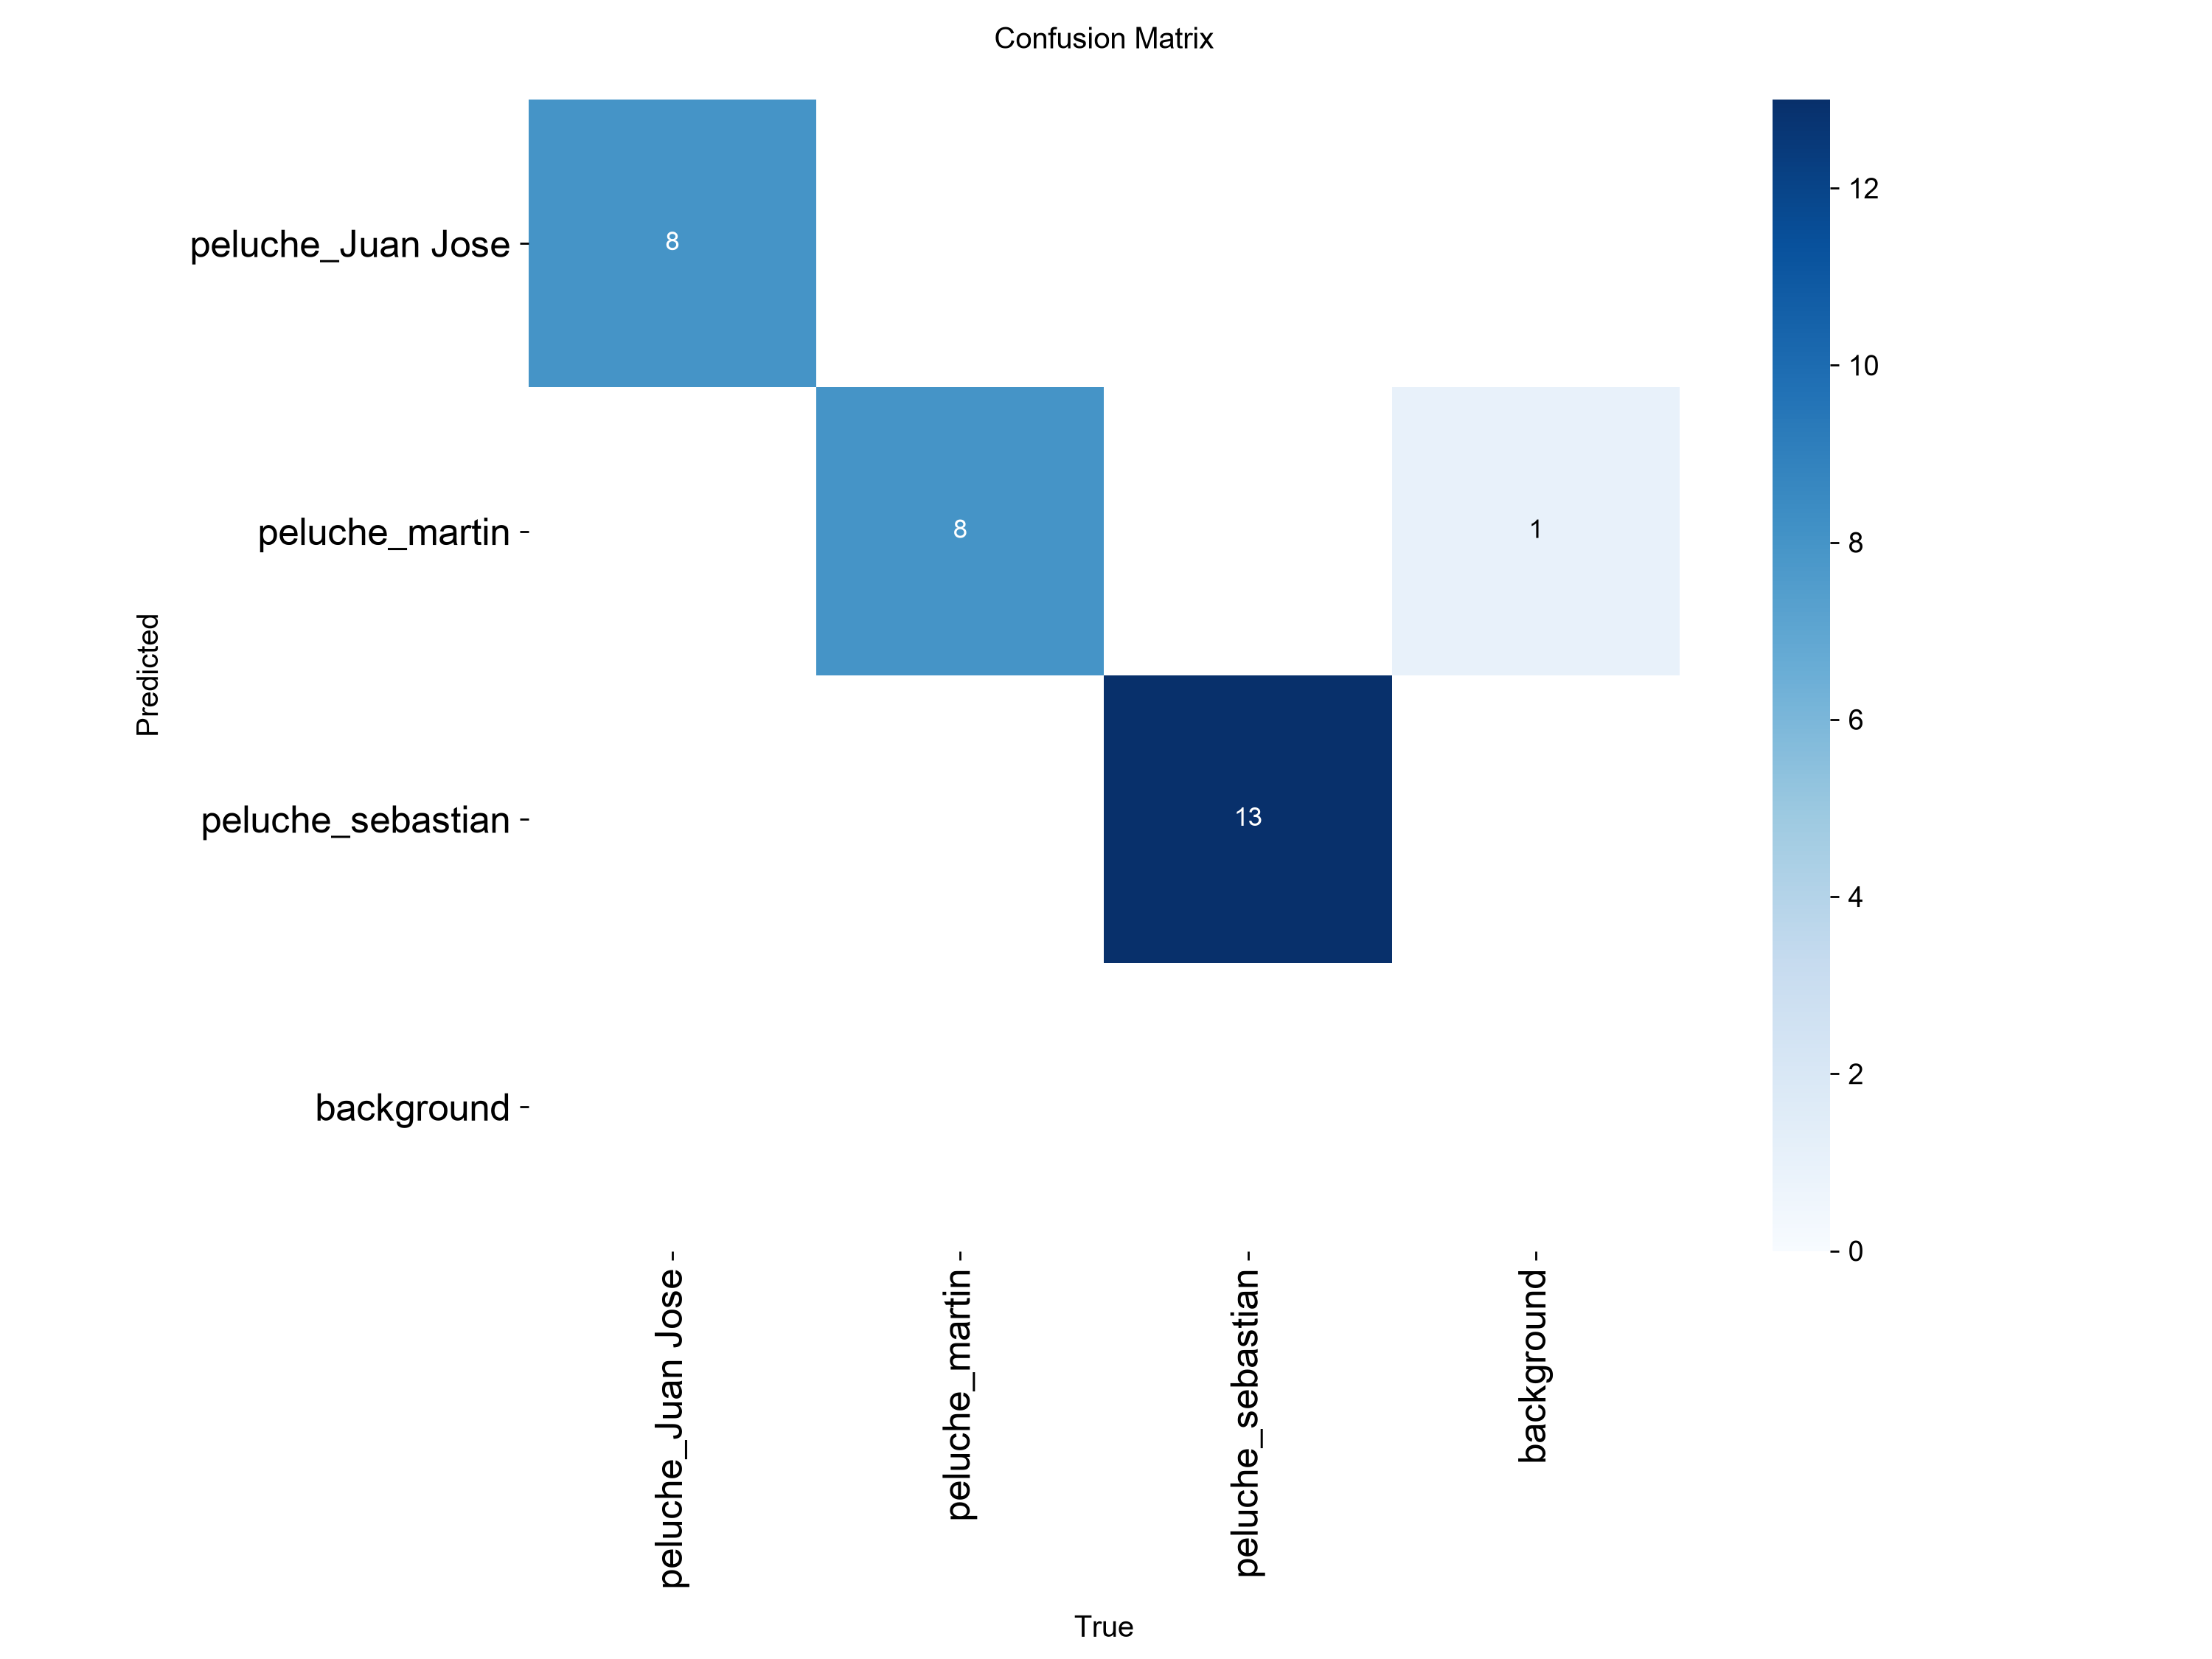

In [12]:
test_metrics = best_model.val(
    data=str(DATA_YAML), split="test", device=DEVICE,
    imgsz=IMAGE_SIZE, batch=BATCH_SIZE, workers=0,
    conf=0.25,
    project=str(OUTPUT_DIR), name="test", exist_ok=True, plots=True,
)
print(f"Test mAP50: {test_metrics.box.map50:.3f}")
print(f"Test mAP50-95: {test_metrics.box.map:.3f}")

# Mostrar la matriz de esta evaluación final, separada de validación.
TEST_DIR = Path(test_metrics.save_dir)
print("Matriz de test — conf=0.25:", TEST_DIR)
display(NotebookImage(filename=str(TEST_DIR / "confusion_matrix.png"), width=1000))


## 9. Predecir imágenes





0: 640x640 1 peluche_Juan Jose, 0.6ms
1: 640x640 1 peluche_Juan Jose, 0.6ms
2: 640x640 1 peluche_martin, 0.6ms
3: 640x640 1 peluche_martin, 0.6ms
4: 640x640 1 peluche_sebastian, 0.6ms
5: 640x640 1 peluche_sebastian, 0.6ms
Speed: 2.0ms preprocess, 0.6ms inference, 3.6ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /Users/martinrestrepocoral/Desktop/IA/yolo_nao/runs/peluches/predict


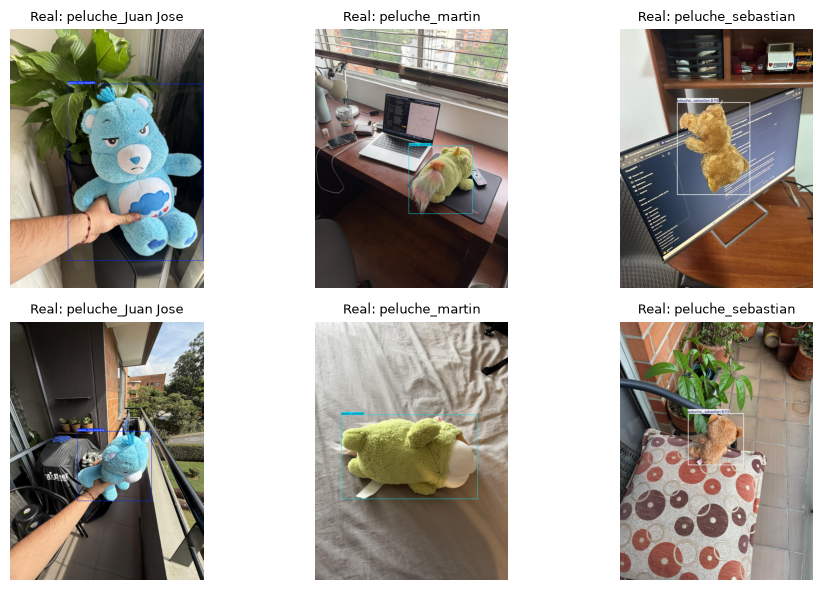

In [ ]:
import random

# Seleccionar ejemplos por su clase real, no por el orden de los archivos.
EXAMPLES_PER_CLASS = 2
rng = random.Random(42)
test_images = sorted(
    p for p in (DATASET_DIR / "test" / "images").iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
)
images_per_class = {class_id: [] for class_id in range(len(CLASS_NAMES))}
for image_path in test_images:
    label_path = DATASET_DIR / "test" / "labels" / f"{image_path.stem}.txt"
    class_ids = {
        int(line.split()[0]) for line in label_path.read_text().splitlines()
        if line.strip()
    }
    for class_id in class_ids:
        images_per_class[class_id].append(image_path)

selected = []
used = set()
for class_id, class_name in enumerate(CLASS_NAMES):
    candidates = [p for p in images_per_class[class_id] if p not in used]
    examples = rng.sample(candidates, min(EXAMPLES_PER_CLASS, len(candidates)))
    if not examples:
        print(f"No hay ejemplos disponibles de {class_name} en test.")
    selected.extend((image_path, class_name) for image_path in examples)
    used.update(examples)
if not selected:
    raise ValueError("No se encontraron imágenes de las clases objetivo en test.")

SOURCE = [str(image_path) for image_path, _ in selected]
predictions = best_model.predict(
    source=SOURCE, conf=0.25, imgsz=IMAGE_SIZE, device=DEVICE,
    save=True, project=str(OUTPUT_DIR), name="predict", exist_ok=True,
)

# Vista compacta: cada columna corresponde a una clase real.
fig, axes = plt.subplots(
    EXAMPLES_PER_CLASS, len(CLASS_NAMES),
    figsize=(10, 6), squeeze=False,
)
for ax in axes.flat:
    ax.axis("off")
class_positions = {class_name: 0 for class_name in CLASS_NAMES}
for prediction, (_, class_name) in zip(predictions, selected):
    column = CLASS_NAMES.index(class_name)
    row = class_positions[class_name]
    class_positions[class_name] += 1
    ax = axes[row, column]
    ax.imshow(prediction.plot(line_width=2, font_size=12)[..., ::-1])
    ax.set_title(f"Real: {class_name}", fontsize=9)
plt.tight_layout()
plt.show()


## 10. Conservar el modelo

El archivo que necesitas para usar tu detector es `weights/best.pt` dentro de la carpeta de esta ejecución. Puede cargarse en otra sesión con `YOLO("ruta/al/best.pt")`. Conserva también el YAML, los parámetros y las métricas para comparar entrenamientos.

La exportación ONNX es opcional y se deja comentada: puede necesitar dependencias adicionales y su compatibilidad debe comprobarse en el equipo donde usarás el modelo.


In [14]:
print("Guarda este archivo:", BEST_WEIGHTS)
# Para cargarlo en otra sesión:
# detector = YOLO("ruta/al/best.pt")
# detector.predict(source="foto_nueva.jpg", save=True)

# Exportación opcional, cuando sepas cómo desplegarás el detector:
# best_model.export(format="onnx")


Guarda este archivo: /Users/martinrestrepocoral/Desktop/IA/yolo_nao/runs/peluches/train/weights/best.pt
